# Orthogonality and Orthonormality

> *"Pythagoras could have predicted deep learning: orthogonality is not just a geometric nicety — it is the reason gradient-based optimization works."*

Interactive theory notebook for §05 Orthogonality and Orthonormality. Covers inner products, Gram-Schmidt, QR decomposition, orthogonal projections, the spectral theorem, and their applications in modern machine learning.

**Companion notes:** [notes.md](notes.md) | **Exercises:** [exercises.ipynb](exercises.ipynb)

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl

try:
    import seaborn as sns
    sns.set_theme(style="whitegrid", palette="colorblind")
    HAS_SNS = True
except ImportError:
    plt.style.use("seaborn-v0_8-whitegrid")
    HAS_SNS = False

mpl.rcParams.update({
    "figure.figsize":    (10, 6),
    "figure.dpi":         120,
    "font.size":           13,
    "axes.titlesize":      15,
    "axes.labelsize":      13,
    "xtick.labelsize":     11,
    "ytick.labelsize":     11,
    "legend.fontsize":     11,
    "legend.framealpha":   0.85,
    "lines.linewidth":      2.0,
    "axes.spines.top":     False,
    "axes.spines.right":   False,
    "savefig.bbox":       "tight",
    "savefig.dpi":         150,
})
np.random.seed(42)
print("Plot setup complete.")

Plot setup complete.


In [2]:
import numpy as np
import numpy.linalg as la
from scipy.linalg import qr, polar, solve_triangular

try:
    import matplotlib.pyplot as plt
    import matplotlib.patches as patches
    plt.style.use('seaborn-v0_8-whitegrid')
    plt.rcParams['figure.figsize'] = [10, 5]
    plt.rcParams['font.size'] = 12
    HAS_MPL = True
except ImportError:
    HAS_MPL = False

try:
    import seaborn as sns
    HAS_SNS = True
except ImportError:
    HAS_SNS = False

np.set_printoptions(precision=6, suppress=True)
np.random.seed(42)

def check(name, got=None, expected=None, cond=None, tol=1e-8):
    if cond is not None:
        ok = cond
    else:
        ok = np.allclose(got, expected, atol=tol, rtol=tol)
    print(f"{'PASS' if ok else 'FAIL'} -- {name}")
    return ok

print('Setup complete. NumPy', np.__version__)


Setup complete. NumPy 2.5.4


---

## 1. Intuition: Why Orthogonality Matters

Orthogonality is the single most powerful structure in linear algebra. When vectors are orthogonal, computations that would otherwise require matrix inversions collapse to simple inner products. This section demonstrates the key computational miracles that orthogonality enables.

In [3]:
# === 1.1 Orthogonality: Geometric Demonstration ===

# In a non-orthogonal basis, expressing a vector requires solving a system
v = np.array([3.0, 2.0])
b1 = np.array([1.0, 0.5])   # non-orthogonal basis
b2 = np.array([0.5, 1.0])
B = np.column_stack([b1, b2])
coords_nonorth = la.solve(B, v)  # requires matrix inverse
print(f'Non-orthogonal: solve Bc = v requires O(n^3) work')
print(f'  Coordinates: {coords_nonorth}')

# In an orthonormal basis, it's just inner products (O(n) work)
q1 = np.array([1.0, 0.0])
q2 = np.array([0.0, 1.0])
c1 = v @ q1   # just an inner product
c2 = v @ q2
print(f'\nOrthonormal: inner products only')
print(f'  Coordinates: ({c1}, {c2})')
print(f'  Reconstruction: {c1*q1 + c2*q2}')

# Verify both give same reconstruction
check('both bases reconstruct v', B @ coords_nonorth, v)
check('ONB reconstructs v', c1*q1 + c2*q2, v)
print('\nKey insight: ONB makes coordinates = inner products (no matrix inversion needed)')


Non-orthogonal: solve Bc = v requires O(n^3) work
  Coordinates: [2.666667 0.666667]

Orthonormal: inner products only
  Coordinates: (3.0, 2.0)
  Reconstruction: [3. 2.]
PASS -- both bases reconstruct v
PASS -- ONB reconstructs v

Key insight: ONB makes coordinates = inner products (no matrix inversion needed)


In [4]:
# === 1.2 Cauchy-Schwarz Inequality Visualization ===

# Demonstrate |<u,v>| <= ||u|| ||v|| for many random pairs
n_tests = 1000
dim = 10
ratios = []
for _ in range(n_tests):
    u = np.random.randn(dim)
    v = np.random.randn(dim)
    lhs = abs(u @ v)
    rhs = la.norm(u) * la.norm(v)
    ratios.append(lhs / rhs)  # should always be <= 1

ratios = np.array(ratios)
print(f'Cauchy-Schwarz test over {n_tests} random pairs:')
print(f'  Max ratio |<u,v>| / (||u|| ||v||) = {ratios.max():.8f}  (should be ≤ 1)')
print(f'  Mean ratio = {ratios.mean():.4f}')
check('Cauchy-Schwarz: all ratios <= 1', cond=bool(np.all(ratios <= 1 + 1e-10)))

# When does equality hold? When u and v are parallel
u_eq = np.array([1.0, 2.0, 3.0])
v_eq = 2.5 * u_eq  # parallel to u
ratio_eq = abs(u_eq @ v_eq) / (la.norm(u_eq) * la.norm(v_eq))
print(f'\nEquality case (parallel vectors): ratio = {ratio_eq:.10f} (should be 1.0)')


Cauchy-Schwarz test over 1000 random pairs:
  Max ratio |<u,v>| / (||u|| ||v||) = 0.80512475  (should be ≤ 1)
  Mean ratio = 0.2626
PASS -- Cauchy-Schwarz: all ratios <= 1

Equality case (parallel vectors): ratio = 1.0000000000 (should be 1.0)


In [5]:
# === 1.3 Inner Product Encodes Angle ===

# cos(theta) = <u,v> / (||u|| ||v||)
test_cases = [
    (np.array([1,0,0]), np.array([0,1,0]), 'e1, e2 (perpendicular)'),
    (np.array([1,0,0]), np.array([1,1,0])/np.sqrt(2), 'e1, 45deg from e1'),
    (np.array([1,0,0]), np.array([-1,0,0]), 'e1, -e1 (antiparallel)'),
    (np.array([1,1,0])/np.sqrt(2), np.array([1,1,1])/np.sqrt(3), 'diag2, diag3'),
]

print('Vector pair                           cos(θ)      angle')
print('-' * 60)
for u, v, name in test_cases:
    cos_t = u @ v / (la.norm(u) * la.norm(v))
    angle_deg = np.degrees(np.arccos(np.clip(cos_t, -1, 1)))
    print(f'{name:<40} {cos_t:7.4f}    {angle_deg:6.1f}°')


Vector pair                           cos(θ)      angle
------------------------------------------------------------
e1, e2 (perpendicular)                    0.0000      90.0°
e1, 45deg from e1                         0.7071      45.0°
e1, -e1 (antiparallel)                   -1.0000     180.0°
diag2, diag3                              0.8165      35.3°


---

## 2. Formal Definitions

### 2.1–2.5: Cauchy-Schwarz, Orthonormality, Parseval, Complements

We verify the key identities numerically.

In [6]:
# === 2.1 Cauchy-Schwarz and Norm Identities ===

# Pythagorean theorem
u = np.array([3.0, 0.0])
v = np.array([0.0, 4.0])
print(f'Pythagorean theorem: u⊥v -> ||u+v||² = ||u||² + ||v||²')
print(f'  ||u+v||² = {la.norm(u+v)**2:.2f}')
print(f'  ||u||² + ||v||² = {la.norm(u)**2 + la.norm(v)**2:.2f}')
check('Pythagorean theorem', la.norm(u+v)**2, la.norm(u)**2 + la.norm(v)**2)

# Parseval's identity with standard basis (trivial ONB)
v_test = np.array([3.0, 1.0, 4.0, 1.0, 5.0])
Q_std = np.eye(5)  # standard ONB
coeffs = Q_std.T @ v_test
parseval_sum = np.sum(coeffs**2)
print(f'\nParseval identity: ||v||² = Σᵢ <v,qᵢ>²')
print(f'  ||v||² = {la.norm(v_test)**2:.2f}')
print(f'  Σᵢ |<v,qᵢ>|² = {parseval_sum:.2f}')
check('Parseval identity (standard basis)', parseval_sum, la.norm(v_test)**2)

# Parseval with a random ONB
M = np.random.randn(5, 5)
Q_rand, _ = la.qr(M)  # random ONB
coeffs_rand = Q_rand.T @ v_test
check('Parseval identity (random ONB)', np.sum(coeffs_rand**2), la.norm(v_test)**2)


Pythagorean theorem: u⊥v -> ||u+v||² = ||u||² + ||v||²
  ||u+v||² = 25.00
  ||u||² + ||v||² = 25.00
PASS -- Pythagorean theorem

Parseval identity: ||v||² = Σᵢ <v,qᵢ>²
  ||v||² = 52.00
  Σᵢ |<v,qᵢ>|² = 52.00
PASS -- Parseval identity (standard basis)
PASS -- Parseval identity (random ONB)


True

In [7]:
# === 2.5 Orthogonal Decomposition ===

# Decompose v into S component and S-perp component
# S = span{q1, q2} in R^4
q1 = np.array([1., 1., 0., 0.]) / np.sqrt(2)
q2 = np.array([0., 0., 1., 1.]) / np.sqrt(2)
Q_S = np.column_stack([q1, q2])  # 4x2 matrix, orthonormal columns

v = np.array([1., 2., 3., 4.])

# Projection onto S
v_S = Q_S @ (Q_S.T @ v)  # = sum_i <v,qi> qi

# Component in S-perp
v_Sperp = v - v_S

print('Orthogonal Decomposition: v = v_S + v_S⊥')
print(f'  v       = {v}')
print(f'  v_S     = {v_S}')
print(f'  v_S⊥   = {v_Sperp}')
print(f'  Sum     = {v_S + v_Sperp}')

check('Reconstruction: v_S + v_Sperp = v', v_S + v_Sperp, v)
check('v_Sperp ⊥ q1', cond=abs(v_Sperp @ q1) < 1e-12)
check('v_Sperp ⊥ q2', cond=abs(v_Sperp @ q2) < 1e-12)

# dim check
print(f'\ndim(S) = 2, dim(S⊥) = 2, dim(R^4) = 4')
print(f'dim(S) + dim(S⊥) = {2 + 2} = dim(R^4) ✓')

# Pythagorean theorem for the decomposition
check('||v||² = ||v_S||² + ||v_S⊥||²',
      la.norm(v)**2, la.norm(v_S)**2 + la.norm(v_Sperp)**2)


Orthogonal Decomposition: v = v_S + v_S⊥
  v       = [1. 2. 3. 4.]
  v_S     = [1.5 1.5 3.5 3.5]
  v_S⊥   = [-0.5  0.5 -0.5  0.5]
  Sum     = [1. 2. 3. 4.]
PASS -- Reconstruction: v_S + v_Sperp = v
PASS -- v_Sperp ⊥ q1
PASS -- v_Sperp ⊥ q2

dim(S) = 2, dim(S⊥) = 2, dim(R^4) = 4
dim(S) + dim(S⊥) = 4 = dim(R^4) ✓
PASS -- ||v||² = ||v_S||² + ||v_S⊥||²


True

---

## 3. Orthogonal Matrices

### 3.1–3.5: Definition, O(n), Condition Number, Eigenvalues, Cayley Transform

In [8]:
# === 3.1 Orthogonal Matrix Properties ===

# Rotation matrix in 2D
theta = np.pi / 3  # 60 degrees
Q_rot = np.array([[np.cos(theta), -np.sin(theta)],
                   [np.sin(theta),  np.cos(theta)]])

print('2D Rotation matrix (theta = pi/3):')
print(Q_rot)
print(f'\nVerifying orthogonality:')
check('Q^T Q = I', Q_rot.T @ Q_rot, np.eye(2))
check('Q Q^T = I', Q_rot @ Q_rot.T, np.eye(2))
check('det(Q) = 1', cond=abs(la.det(Q_rot) - 1) < 1e-12)

# Isometry: preserves norms
x = np.array([3.0, 4.0])
Qx = Q_rot @ x
print(f'\nIsometry test:')
print(f'  ||x|| = {la.norm(x):.6f}')
print(f'  ||Qx|| = {la.norm(Qx):.6f}')
check('||Qx|| = ||x||', la.norm(Qx), la.norm(x))

# Preserves inner products
y = np.array([1.0, 2.0])
Qy = Q_rot @ y
check('<Qx, Qy> = <x, y>', Qx @ Qy, x @ y)

# Condition number
kappa_Q = la.cond(Q_rot)
print(f'\nCondition number of Q_rot: {kappa_Q:.6f} (should be 1.0)')


2D Rotation matrix (theta = pi/3):
[[ 0.5      -0.866025]
 [ 0.866025  0.5     ]]

Verifying orthogonality:
PASS -- Q^T Q = I
PASS -- Q Q^T = I
PASS -- det(Q) = 1

Isometry test:
  ||x|| = 5.000000
  ||Qx|| = 5.000000
PASS -- ||Qx|| = ||x||
PASS -- <Qx, Qy> = <x, y>

Condition number of Q_rot: 1.000000 (should be 1.0)


In [9]:
# === 3.2 Orthogonal Group O(n) ===

# Generate random orthogonal matrices via QR
def random_orthogonal(n, seed=None):
    rng = np.random.default_rng(seed)
    M = rng.standard_normal((n, n))
    Q, R = la.qr(M)
    Q *= np.sign(np.diag(R))  # ensure uniform distribution
    return Q

Q1 = random_orthogonal(4, seed=1)
Q2 = random_orthogonal(4, seed=2)

print('Closure under multiplication:')
Q3 = Q1 @ Q2
check('Q1 @ Q2 is orthogonal', Q3.T @ Q3, np.eye(4))

print('\nInverse = transpose:')
check('Q^{-1} = Q^T', la.inv(Q1), Q1.T)

print('\nDeterminant is ±1:')
for i, Q in enumerate([Q1, Q2, Q3]):
    d = la.det(Q)
    print(f'  det(Q{i+1}) = {d:.6f}')

# Reflection (det = -1)
Q_refl = np.diag([-1., 1., 1., 1.])  # flip first coordinate
check('Reflection is orthogonal', Q_refl.T @ Q_refl, np.eye(4))
print(f'  det(Q_refl) = {la.det(Q_refl):.1f}  (reflection: det = -1)')


Closure under multiplication:
PASS -- Q1 @ Q2 is orthogonal

Inverse = transpose:
PASS -- Q^{-1} = Q^T

Determinant is ±1:
  det(Q1) = -1.000000
  det(Q2) = 1.000000
  det(Q3) = -1.000000
PASS -- Reflection is orthogonal
  det(Q_refl) = -1.0  (reflection: det = -1)


---

## 4. Orthogonal Projections

Orthogonal projection is the fundamental operation connecting orthogonality to computation. Every least-squares problem, every PCA step, and every attention head involves a projection.

In [10]:
# === 4.1 Orthogonal Projection Formula ===

# Projection onto a 1D subspace (unit vector)
u_hat = np.array([1., 1., 0.]) / np.sqrt(2)  # unit vector
v = np.array([2., 1., 3.])

proj_v = (v @ u_hat) * u_hat
print(f'Projection of v = {v}')
print(f'onto u_hat = {u_hat}')
print(f'proj = {proj_v}')
print(f'coefficient <v, u_hat> = {v @ u_hat:.4f}')

# Verify orthogonality of residual
residual = v - proj_v
print(f'\nResidue v - proj = {residual}')
print(f'<residue, u_hat> = {residual @ u_hat:.2e}  (should be ~0)')
check('Residual ⊥ u_hat', cond=abs(residual @ u_hat) < 1e-12)

# Projection matrix P = u_hat u_hat^T
P1D = np.outer(u_hat, u_hat)
check('P idempotent: P^2 = P', P1D @ P1D, P1D)
check('P symmetric: P^T = P', P1D.T, P1D)
check('P v = proj_v', P1D @ v, proj_v)


Projection of v = [2. 1. 3.]
onto u_hat = [0.707107 0.707107 0.      ]
proj = [1.5 1.5 0. ]
coefficient <v, u_hat> = 2.1213

Residue v - proj = [ 0.5 -0.5  3. ]
<residue, u_hat> = 3.24e-16  (should be ~0)
PASS -- Residual ⊥ u_hat
PASS -- P idempotent: P^2 = P
PASS -- P symmetric: P^T = P
PASS -- P v = proj_v


True

In [11]:
# === 4.2 Projection onto Higher-Dimensional Subspace ===

# Build an ONB for a 2D subspace of R^4
a1 = np.array([1., 1., 0., 0.])
a2 = np.array([0., 1., 1., 0.])

# Gram-Schmidt to get ONB
q1 = a1 / la.norm(a1)
u2 = a2 - (a2 @ q1) * q1
q2 = u2 / la.norm(u2)
Q_sub = np.column_stack([q1, q2])  # 4x2 with Q^T Q = I

check('Q^T Q = I2', Q_sub.T @ Q_sub, np.eye(2))

# Project v onto subspace
v = np.array([1., 2., 3., 4.])
P_sub = Q_sub @ Q_sub.T  # 4x4 projection matrix
v_proj = P_sub @ v
v_perp = v - v_proj

print(f'Projection onto S = span(q1, q2):')
print(f'  v_S    = {v_proj}')
print(f'  v_S⊥  = {v_perp}')

check('P idempotent', P_sub @ P_sub, P_sub)
check('P symmetric', P_sub.T, P_sub)
check('v_perp ⊥ q1', cond=abs(v_perp @ q1) < 1e-12)
check('v_perp ⊥ q2', cond=abs(v_perp @ q2) < 1e-12)
check('||v||² = ||v_S||² + ||v_perp||²',
      la.norm(v)**2, la.norm(v_proj)**2 + la.norm(v_perp)**2)


PASS -- Q^T Q = I2
Projection onto S = span(q1, q2):
  v_S    = [0.333333 2.666667 2.333333 0.      ]
  v_S⊥  = [ 0.666667 -0.666667  0.666667  4.      ]
PASS -- P idempotent
PASS -- P symmetric
PASS -- v_perp ⊥ q1
PASS -- v_perp ⊥ q2
PASS -- ||v||² = ||v_S||² + ||v_perp||²


True

<>:33: SyntaxWarning: invalid escape sequence '\h'
<>:33: SyntaxWarning: invalid escape sequence '\h'
/tmp/ipykernel_65973/2822393928.py:33: SyntaxWarning: invalid escape sequence '\h'
  ax.set_title('Orthogonal Projection onto S = span{$\hat{u}$}')


/tmp/ipykernel_65973/2822393928.py:52: UserWarning: Glyph 8869 (\N{UP TACK}) missing from font(s) Liberation Sans.
  plt.tight_layout()
/tmp/ipykernel_65973/2822393928.py:53: UserWarning: Glyph 8869 (\N{UP TACK}) missing from font(s) Liberation Sans.
  plt.savefig('/tmp/orth_projection.png', dpi=100, bbox_inches='tight')


/tmp/venv15/lib/python3.13/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 8869 (\N{UP TACK}) missing from font(s) Liberation Sans.
  fig.canvas.print_figure(bytes_io, **kw)


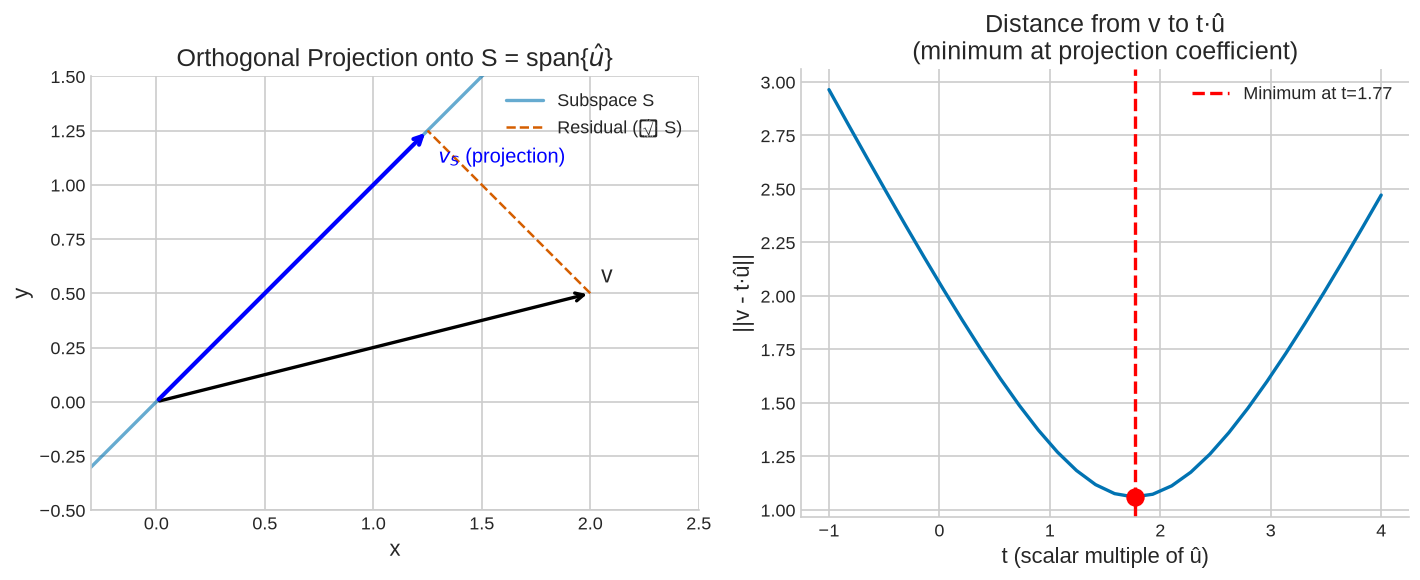

Figure saved.


In [12]:
# === 4.3 Best Approximation: Projection is the Nearest Point ===

# Visualize projection in R^2 and verify best-approximation property
if HAS_MPL:
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))

    # Left: 2D projection visualization
    ax = axes[0]
    origin = np.array([0, 0])
    u_hat2 = np.array([1., 1.]) / np.sqrt(2)
    v2 = np.array([2., 0.5])
    proj2 = (v2 @ u_hat2) * u_hat2

    # Draw the subspace line
    t = np.linspace(-0.5, 3, 100)
    ax.plot(t * u_hat2[0], t * u_hat2[1], 'b-', linewidth=2, label='Subspace S', alpha=0.6)

    # Draw v and projection
    ax.annotate('', xy=v2, xytext=origin,
               arrowprops=dict(arrowstyle='->', color='black', lw=2))
    ax.annotate('', xy=proj2, xytext=origin,
               arrowprops=dict(arrowstyle='->', color='blue', lw=2.5))
    ax.plot([v2[0], proj2[0]], [v2[1], proj2[1]], 'r--', linewidth=1.5, label='Residual (⊥ S)')

    # Mark the right angle
    ax.text(v2[0] + 0.05, v2[1] + 0.05, 'v', fontsize=14)
    ax.text(proj2[0] + 0.05, proj2[1] - 0.15, r'$v_S$ (projection)', fontsize=12, color='blue')

    ax.set_xlim(-0.3, 2.5)
    ax.set_ylim(-0.5, 1.5)
    ax.set_aspect('equal')
    ax.legend()
    ax.set_title('Orthogonal Projection onto S = span{$\hat{u}$}')
    ax.set_xlabel('x')
    ax.set_ylabel('y')

    # Right: distances to subspace
    ax2 = axes[1]
    n_pts = 30
    t_vals = np.linspace(-1, 4, n_pts)
    distances = [la.norm(v2 - t * u_hat2) for t in t_vals]
    t_opt = v2 @ u_hat2  # optimal t (= the projection coefficient)

    ax2.plot(t_vals, distances, 'b-', linewidth=2)
    ax2.axvline(t_opt, color='red', linestyle='--', label=f'Minimum at t={t_opt:.2f}')
    ax2.scatter([t_opt], [la.norm(v2 - t_opt * u_hat2)], color='red', s=100, zorder=5)
    ax2.set_xlabel('t (scalar multiple of û)')
    ax2.set_ylabel('||v - t·û||')
    ax2.set_title('Distance from v to t·û\n(minimum at projection coefficient)')
    ax2.legend()

    plt.tight_layout()
    plt.savefig('/tmp/orth_projection.png', dpi=100, bbox_inches='tight')
    plt.show()
    print('Figure saved.')
else:
    # Numerical demonstration
    u_hat2 = np.array([1., 1.]) / np.sqrt(2)
    v2 = np.array([2., 0.5])
    proj2 = (v2 @ u_hat2) * u_hat2
    t_opt = v2 @ u_hat2

    t_vals = np.linspace(-1, 4, 20)
    distances = [la.norm(v2 - t * u_hat2) for t in t_vals]
    print(f'Projection coefficient t_opt = {t_opt:.4f}')
    print(f'Minimum distance = {min(distances):.4f}')
    print(f'Distance at t_opt = {la.norm(v2 - t_opt * u_hat2):.4f}')
    check('t_opt minimizes distance', min(distances), la.norm(v2 - t_opt * u_hat2), tol=1e-4)


---

## 5. Gram-Schmidt Orthogonalization

Gram-Schmidt is the algorithmic heart of orthogonality: given any basis, produce an orthonormal one. We implement both Classical (CGS) and Modified (MGS) versions and study their numerical stability.

In [13]:
# === 5.1–5.2 Classical vs Modified Gram-Schmidt ===

def cgs(A):
    """Classical Gram-Schmidt."""
    m, n = A.shape
    Q = np.zeros_like(A, dtype=float)
    R = np.zeros((n, n))
    for j in range(n):
        v = A[:, j].copy().astype(float)
        for i in range(j):
            R[i, j] = Q[:, i] @ A[:, j]
            v -= R[i, j] * Q[:, i]
        R[j, j] = la.norm(v)
        Q[:, j] = v / R[j, j]
    return Q, R

def mgs(A):
    """Modified Gram-Schmidt."""
    m, n = A.shape
    Q = A.astype(float).copy()
    R = np.zeros((n, n))
    for j in range(n):
        R[j, j] = la.norm(Q[:, j])
        Q[:, j] /= R[j, j]
        for k in range(j+1, n):
            R[j, k] = Q[:, j] @ Q[:, k]
            Q[:, k] -= R[j, k] * Q[:, j]
    return Q, R

# Test on well-conditioned matrix
A = np.array([[1., 1., 0.],
              [1., 0., 1.],
              [0., 1., 1.]])

Q_cgs, R_cgs = cgs(A)
Q_mgs, R_mgs = mgs(A)

print('Testing Gram-Schmidt on well-conditioned matrix:')
check('CGS: Q^T Q = I', Q_cgs.T @ Q_cgs, np.eye(3))
check('CGS: Q R = A', Q_cgs @ R_cgs, A)
check('MGS: Q^T Q = I', Q_mgs.T @ Q_mgs, np.eye(3))
check('MGS: Q R = A', Q_mgs @ R_mgs, A)
print(f'\nQ from CGS:\n{Q_cgs}')
print(f'R from CGS:\n{R_cgs}')


Testing Gram-Schmidt on well-conditioned matrix:
PASS -- CGS: Q^T Q = I
PASS -- CGS: Q R = A
PASS -- MGS: Q^T Q = I
PASS -- MGS: Q R = A

Q from CGS:
[[ 0.707107  0.408248 -0.57735 ]
 [ 0.707107 -0.408248  0.57735 ]
 [ 0.        0.816497  0.57735 ]]
R from CGS:
[[1.414214 0.707107 0.707107]
 [0.       1.224745 0.408248]
 [0.       0.       1.154701]]


Orthogonality error ||Q^T Q - I||_F for Hilbert matrix:
   n             CGS             MGS     Householder
   4        4.89e-11        4.22e-13        7.87e-16
   5        7.78e-08        1.71e-11        9.77e-16
   6        2.84e-04        1.01e-09        8.60e-16
   7        8.17e-01        1.30e-08        9.47e-16
   8        1.42e+00        3.62e-07        7.33e-16
   9        2.45e+00        5.52e-06        9.64e-16
  10        3.47e+00        2.48e-04        1.40e-15
  11        4.07e+00        9.86e-03        1.86e-15
  12        5.48e+00        1.61e-01        1.72e-15
  13        6.47e+00        1.40e+00        1.77e-15

Conclusion: Householder > MGS >> CGS for ill-conditioned matrices


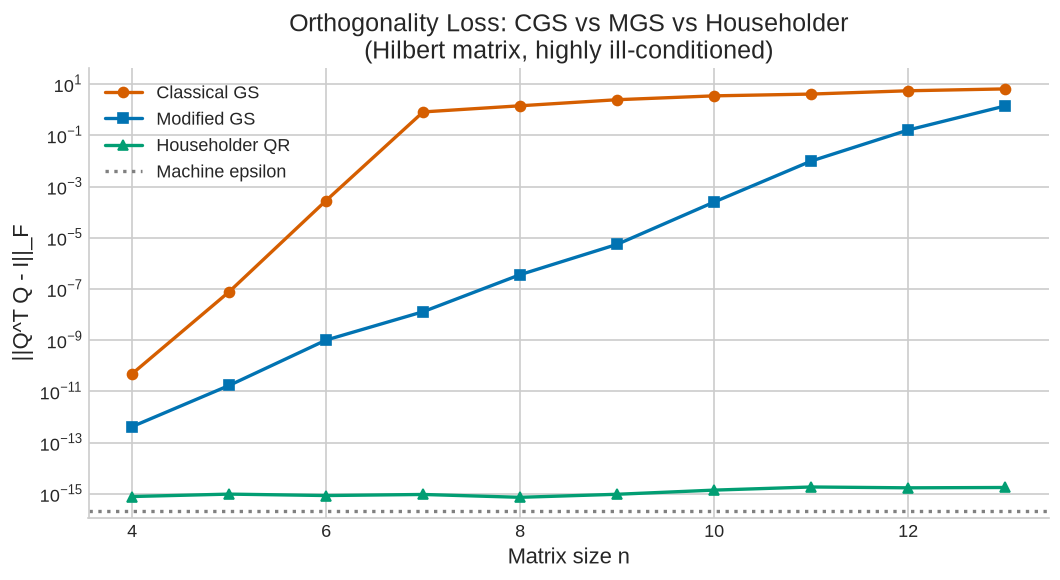

In [14]:
# === 5.2 Numerical Stability: CGS vs MGS on Ill-Conditioned Matrix ===

def orthogonality_error(Q):
    """Frobenius norm of Q^T Q - I."""
    n = Q.shape[1]
    return la.norm(Q.T @ Q - np.eye(n), 'fro')

# Hilbert matrix: famously ill-conditioned
ns = range(4, 14)
errs_cgs, errs_mgs, errs_house = [], [], []

for n in ns:
    H = 1.0 / (np.arange(1, n+1)[:, None] + np.arange(1, n+1)[None, :] - 1)
    Q_c, _ = cgs(H)
    Q_m, _ = mgs(H)
    Q_h, _ = la.qr(H)  # Householder (numpy's implementation)
    errs_cgs.append(orthogonality_error(Q_c))
    errs_mgs.append(orthogonality_error(Q_m))
    errs_house.append(orthogonality_error(Q_h))

ns_list = list(ns)
print('Orthogonality error ||Q^T Q - I||_F for Hilbert matrix:')
print(f'{"n":>4}  {"CGS":>14}  {"MGS":>14}  {"Householder":>14}')
for i, n in enumerate(ns_list):
    print(f'{n:>4}  {errs_cgs[i]:14.2e}  {errs_mgs[i]:14.2e}  {errs_house[i]:14.2e}')

print('\nConclusion: Householder > MGS >> CGS for ill-conditioned matrices')

if HAS_MPL:
    plt.figure(figsize=(9, 5))
    plt.semilogy(ns_list, errs_cgs, 'r-o', label='Classical GS', linewidth=2)
    plt.semilogy(ns_list, errs_mgs, 'b-s', label='Modified GS', linewidth=2)
    plt.semilogy(ns_list, errs_house, 'g-^', label='Householder QR', linewidth=2)
    plt.axhline(np.finfo(float).eps, color='gray', linestyle=':', label='Machine epsilon')
    plt.xlabel('Matrix size n')
    plt.ylabel('||Q^T Q - I||_F')
    plt.title('Orthogonality Loss: CGS vs MGS vs Householder\n(Hilbert matrix, highly ill-conditioned)')
    plt.legend()
    plt.tight_layout()
    plt.savefig('/tmp/orth_stability.png', dpi=100, bbox_inches='tight')
    plt.show()


---

## 6. Householder Reflectors

Householder reflectors are the numerically stable way to perform orthogonal reductions. Each reflector zeros out a column below the diagonal with a single orthogonal transformation.

In [15]:
# === 6.1 Householder Reflector Construction ===

def householder_reflector(a):
    """Build H = I - 2nn^T such that Ha = -||a||e1.
    Sign chosen to avoid cancellation."""
    n = len(a)
    v = a.copy().astype(float)
    # Add sign(a[0])*||a|| to first component
    sign = 1.0 if a[0] >= 0 else -1.0
    v[0] += sign * la.norm(a)
    v /= la.norm(v)  # normalize to get n
    H = np.eye(n) - 2 * np.outer(v, v)
    return H

# Test: zero out components of a below first entry
a = np.array([4., 3., 0.])
H = householder_reflector(a)

print(f'a = {a},  ||a|| = {la.norm(a):.4f}')
print(f'H a = {H @ a}')
print(f'Expected: [{-la.norm(a):.4f}, 0., 0.] or [{la.norm(a):.4f}, 0., 0.]')
check('H symmetric: H^T = H', H.T, H)
check('H orthogonal: H^T H = I', H.T @ H, np.eye(3))
check('H involutory: H^2 = I', H @ H, np.eye(3))
check('|det(H)| = 1', cond=abs(abs(la.det(H)) - 1) < 1e-12)
print(f'det(H) = {la.det(H):.4f}  (reflection: det = -1)')

# Geometric verification: Ha zeros out lower components
Ha = H @ a
print(f'\nGeometric result: Ha = {Ha}')
print(f'Components below first: {Ha[1:]}')
check('Lower components zeroed', Ha[1:], np.zeros(2))


a = [4. 3. 0.],  ||a|| = 5.0000
H a = [-5.  0.  0.]
Expected: [-5.0000, 0., 0.] or [5.0000, 0., 0.]
PASS -- H symmetric: H^T = H
PASS -- H orthogonal: H^T H = I
PASS -- H involutory: H^2 = I
PASS -- |det(H)| = 1
det(H) = -1.0000  (reflection: det = -1)

Geometric result: Ha = [-5.  0.  0.]
Components below first: [0. 0.]
PASS -- Lower components zeroed


True

---

## 7. QR Decomposition: Theory and Applications

QR decomposition is the workhorse of numerical linear algebra. We demonstrate existence, uniqueness, and the key application: stable least squares.

In [16]:
# === 7.2 Least Squares via QR vs Normal Equations ===

# Polynomial fitting: design matrix (Vandermonde)
m, d = 20, 8  # m data points, degree-d polynomial
np.random.seed(0)
x = np.linspace(0, 1, m)
y_true = np.sin(2 * np.pi * x)
y = y_true + 0.1 * np.random.randn(m)

# Design matrix: A[i,j] = x[i]^j
A = np.vander(x, d+1, increasing=True)  # m x (d+1)

# Method 1: Normal equations (squares condition number)
ATA = A.T @ A
ATb = A.T @ y
c_normal = la.solve(ATA, ATb)

# Method 2: QR decomposition (stable)
Q_qr, R_qr = la.qr(A)  # full QR
c_qr = solve_triangular(R_qr, Q_qr.T @ y)

# Condition numbers
kappa_A = la.cond(A)
kappa_ATA = la.cond(ATA)
print(f'Condition numbers:')
print(f'  kappa(A)   = {kappa_A:.2e}')
print(f'  kappa(A^T A) = {kappa_ATA:.2e}  (approximately kappa(A)^2)')
print(f'  Ratio: {kappa_ATA / kappa_A**2:.3f}  (should be ~1)')

# Compare residuals
res_normal = la.norm(A @ c_normal - y)
res_qr = la.norm(A @ c_qr - y)
print(f'\nResiduals:')
print(f'  Normal equations: ||Ac - y|| = {res_normal:.8f}')
print(f'  QR factorization: ||Ac - y|| = {res_qr:.8f}')

# Compare coefficients
coeff_diff = la.norm(c_normal - c_qr)
print(f'  ||c_normal - c_qr|| = {coeff_diff:.2e}')
print(f'\nBoth methods agree on residual (same LS solution), but')
print(f'QR is more stable when kappa is large.')


Condition numbers:
  kappa(A)   = 6.22e+05
  kappa(A^T A) = 3.87e+11  (approximately kappa(A)^2)
  Ratio: 1.000  (should be ~1)

Residuals:
  Normal equations: ||Ac - y|| = 0.25200527
  QR factorization: ||Ac - y|| = 0.25200527
  ||c_normal - c_qr|| = 5.57e-02

Both methods agree on residual (same LS solution), but
QR is more stable when kappa is large.


---

## 8. The Spectral Theorem for Symmetric Matrices

Every symmetric matrix can be diagonalized by an orthogonal matrix. This underlies PCA, Hessian analysis, and the geometry of neural network loss surfaces.

In [17]:
# === 8.1 Spectral Decomposition ===
A = np.array([[4., 2., 0.],
              [2., 3., 1.],
              [0., 1., 2.]])

eigvals, Q = np.linalg.eigh(A)
print(f'Eigenvalues: {eigvals}  (all real — spectral theorem)')
check('Q is orthogonal: Q^T Q = I', Q.T @ Q, np.eye(3))
Lambda = np.diag(eigvals)
check('Spectral decomp: Q Lambda Q^T = A', Q @ Lambda @ Q.T, A)

# Each eigenpair A q_i = lambda_i q_i
for i in range(3):
    check(f'A q{i+1} = lambda{i+1} q{i+1}', A @ Q[:,i], eigvals[i]*Q[:,i])


Eigenvalues: [0.854897 2.476024 5.669079]  (all real — spectral theorem)
PASS -- Q is orthogonal: Q^T Q = I
PASS -- Spectral decomp: Q Lambda Q^T = A
PASS -- A q1 = lambda1 q1
PASS -- A q2 = lambda2 q2
PASS -- A q3 = lambda3 q3


Eigenvalues: lambda_min=2.0, lambda_max=4.0
Rayleigh quotient range: [2.000001, 3.999999]
Eigenvalue range:         [2.000000, 4.000000]
PASS -- Min Rayleigh = lambda_min
PASS -- Max Rayleigh = lambda_max


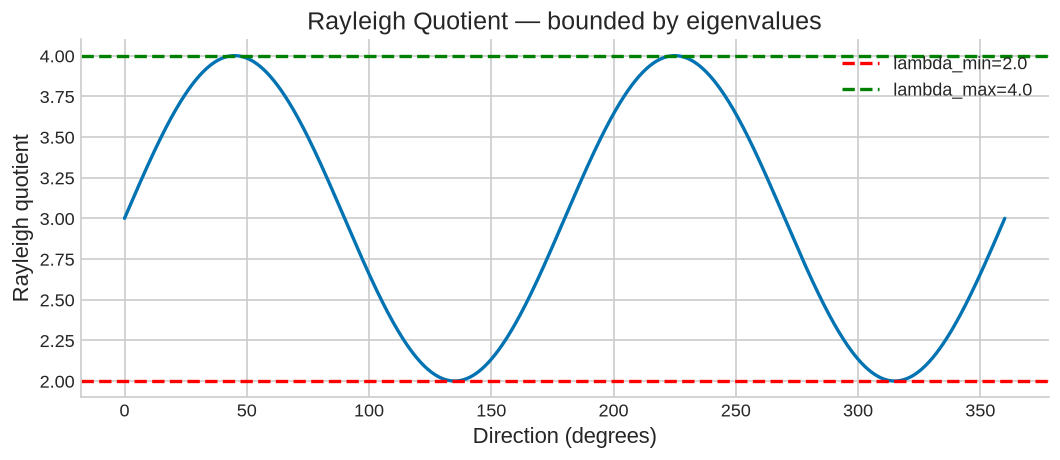

In [18]:
# === 8.2 Rayleigh Quotient ===
A2 = np.array([[3., 1.], [1., 3.]])
lam_min, lam_max = np.linalg.eigvalsh(A2)
print(f'Eigenvalues: lambda_min={lam_min}, lambda_max={lam_max}')

# Rayleigh quotient over all unit-vector directions
thetas = np.linspace(0, 2*np.pi, 1000)
rq = np.array([(np.array([np.cos(t),np.sin(t)]) @ A2 @ np.array([np.cos(t),np.sin(t)]))
               for t in thetas])
print(f'Rayleigh quotient range: [{rq.min():.6f}, {rq.max():.6f}]')
print(f'Eigenvalue range:         [{lam_min:.6f}, {lam_max:.6f}]')
check('Min Rayleigh = lambda_min', rq.min(), lam_min, tol=1e-3)
check('Max Rayleigh = lambda_max', rq.max(), lam_max, tol=1e-3)

if HAS_MPL:
    plt.figure(figsize=(9,4))
    plt.plot(np.degrees(thetas), rq, 'b-', lw=2)
    plt.axhline(lam_min, color='red', ls='--', label=f'lambda_min={lam_min}')
    plt.axhline(lam_max, color='green', ls='--', label=f'lambda_max={lam_max}')
    plt.xlabel('Direction (degrees)'); plt.ylabel('Rayleigh quotient')
    plt.title('Rayleigh Quotient — bounded by eigenvalues')
    plt.legend(); plt.tight_layout(); plt.show()


In [19]:
# === 8.3 Positive Definiteness via Spectral Theorem ===

matrices = {
    'PD  [[4,1],[1,3]]': np.array([[4.,1.],[1.,3.]]),
    'PSD [[1,1],[1,1]]': np.array([[1.,1.],[1.,1.]]),
    'Indef [[2,-3],[-3,1]]': np.array([[2.,-3.],[-3.,1.]]),
    'ND  [[-4,-1],[-1,-3]]': np.array([[-4.,-1.],[-1.,-3.]]),
}

print(f'{'Matrix':<28}  Eigenvalues         Definite?')
print('-'*60)
for name, M in matrices.items():
    eigs = np.linalg.eigvalsh(M)
    if np.all(eigs > 0): defn = 'Positive Definite'
    elif np.all(eigs >= 0): defn = 'Positive Semidefinite'
    elif np.all(eigs < 0): defn = 'Negative Definite'
    else: defn = 'Indefinite'
    print(f'{name:<28}  {str(eigs):<20}  {defn}')


Matrix                        Eigenvalues         Definite?
------------------------------------------------------------
PD  [[4,1],[1,3]]             [2.381966 4.618034]   Positive Definite
PSD [[1,1],[1,1]]             [0. 2.]               Positive Semidefinite
Indef [[2,-3],[-3,1]]         [-1.541381  4.541381]  Indefinite
ND  [[-4,-1],[-1,-3]]         [-4.618034 -2.381966]  Negative Definite


---

## 9. DFT as a Unitary Transform

The Discrete Fourier Transform is orthogonality in disguise: complex exponentials form an orthonormal basis for $\mathbb{C}^n$.

In [20]:
# === 9.3 DFT Unitarity and Parseval ===
n = 8
omega = np.exp(-2j * np.pi / n)
j = np.arange(n)
F = omega ** np.outer(j, j)          # DFT matrix
F_norm = F / np.sqrt(n)             # unitary version

err = np.max(np.abs(F_norm @ F_norm.conj().T - np.eye(n)))
print(f'Unitarity: max|F/sqrt(n) (F/sqrt(n))* - I| = {err:.2e}')
check('DFT/sqrt(n) is unitary', cond=err < 1e-12)

# Parseval
x = np.random.randn(n)
x_hat = F @ x
check('Parseval: ||x_hat||^2/n = ||x||^2',
      np.real(x_hat @ x_hat.conj()) / n, x @ x)

# DFT columns are orthonormal
for k in range(3):
    ip = float(np.real(F_norm[:,0].conj() @ F_norm[:,k+1]))
    print(f'  <f_0, f_{k+1}> = {ip:.2e}  (should be ~0)')


Unitarity: max|F/sqrt(n) (F/sqrt(n))* - I| = 1.03e-15
PASS -- DFT/sqrt(n) is unitary
PASS -- Parseval: ||x_hat||^2/n = ||x||^2
  <f_0, f_1> = -1.38e-16  (should be ~0)
  <f_0, f_2> = -1.17e-16  (should be ~0)
  <f_0, f_3> = -8.52e-17  (should be ~0)


---

## 10. Applications in Machine Learning

In [21]:
# === 10.1 Orthogonal Initialization: Gradient Norm Stability ===
n_dim, L_values = 32, [1, 2, 5, 10, 20]
n_trials = 15

print(f'{'L':>5}  {'Gaussian σ_1':>14}  {'Orthogonal σ_1':>16}')
for L in L_values:
    g_norms, o_norms = [], []
    for _ in range(n_trials):
        Wg = [np.random.randn(n_dim,n_dim)/np.sqrt(n_dim) for _ in range(L)]
        pg = Wg[0].copy()
        for W in Wg[1:]: pg = pg @ W
        g_norms.append(la.norm(pg, 2))

        Wo = []
        for _ in range(L):
            Q, _ = la.qr(np.random.randn(n_dim,n_dim))
            Wo.append(Q)
        po = Wo[0].copy()
        for W in Wo[1:]: po = po @ W
        o_norms.append(la.norm(po, 2))
    print(f'{L:>5}  {np.mean(g_norms):14.4f}  {np.mean(o_norms):16.4f}')
print('Orthogonal init: spectral norm stays ≈ 1.0 for any depth')


    L    Gaussian σ_1    Orthogonal σ_1
    1          1.8991            1.0000
    2          2.4236            1.0000
    5          3.2939            1.0000
   10          4.2108            1.0000
   20          5.1021            1.0000
Orthogonal init: spectral norm stays ≈ 1.0 for any depth


In [22]:
# === 10.2 RoPE: Rotary Position Embeddings ===
def rope_R(pos, dim, base=10000):
    d2 = dim // 2
    thetas = base ** (-2*np.arange(d2)/dim)
    angles = pos * thetas
    R = np.zeros((dim, dim))
    for i in range(d2):
        c, s = np.cos(angles[i]), np.sin(angles[i])
        R[2*i:2*i+2, 2*i:2*i+2] = [[c,-s],[s,c]]
    return R

dim = 8
print('RoPE property: R_m^T R_n = R_{n-m}  (encodes relative position)')
for m, n_pos in [(2,5), (1,4), (0,3)]:
    Rm, Rn, Rrel = rope_R(m,dim), rope_R(n_pos,dim), rope_R(n_pos-m,dim)
    check(f'R_{m}^T R_{n_pos} = R_{n_pos-m}', Rm.T @ Rn, Rrel)
check('RoPE matrix is orthogonal', rope_R(7,dim).T @ rope_R(7,dim), np.eye(dim))


RoPE property: R_m^T R_n = R_{n-m}  (encodes relative position)
PASS -- R_2^T R_5 = R_3
PASS -- R_1^T R_4 = R_3
PASS -- R_0^T R_3 = R_3
PASS -- RoPE matrix is orthogonal


True

In [23]:
# === 10.3 Spectral Normalization ===
np.random.seed(42)
W = np.random.randn(64, 64)
sigma_1 = la.svd(W, compute_uv=False)[0]
W_sn = W / sigma_1
print(f'sigma_1(W) = {sigma_1:.4f}')
print(f'sigma_1(W/sigma_1) = {la.svd(W_sn, compute_uv=False)[0]:.6f}  (should be 1.0)')
check('Spectrally normalized sigma_1 = 1', la.svd(W_sn,compute_uv=False)[0], 1.0)

# All singular values after normalization
svs = la.svd(W_sn, compute_uv=False)
print(f'Singular values range: [{svs.min():.4f}, {svs.max():.4f}]')
print('Only sigma_1 is clamped to 1; others remain < 1 (not full orthogonal)')


sigma_1(W) = 15.3515
sigma_1(W/sigma_1) = 1.000000  (should be 1.0)
PASS -- Spectrally normalized sigma_1 = 1
Singular values range: [0.0088, 1.0000]
Only sigma_1 is clamped to 1; others remain < 1 (not full orthogonal)


In [24]:
# === Polar Decomposition: Nearest Orthogonal Matrix ===
from scipy.linalg import polar

A = np.random.randn(4, 4)
Q_p, S_p = polar(A)          # A = Q S
U, sv, Vt = la.svd(A)
Q_svd = U @ Vt               # = polar Q factor

check('Q^T Q = I', Q_p.T @ Q_p, np.eye(4))
check('S symmetric', S_p, S_p.T)
check('A = Q S', Q_p @ S_p, A)
check('Polar Q = U V^T', Q_p, Q_svd)

# Muon: Newton-Schulz orthogonalization
G = np.random.randn(32, 32)     # gradient matrix
Q_exact, _ = polar(G)
X = G / la.norm(G)
print('Newton-Schulz iterations toward Q = polar(G):')
for step in range(7):
    err = la.norm(X - Q_exact, 'fro')
    print(f'  iter {step}: ||X-Q||_F = {err:.3e}')
    X = 1.5*X - 0.5*X @ X.T @ X


PASS -- Q^T Q = I
PASS -- S symmetric
PASS -- A = Q S
PASS -- Polar Q = U V^T
Newton-Schulz iterations toward Q = polar(G):
  iter 0: ||X-Q||_F = 4.845e+00
  iter 1: ||X-Q||_F = 4.484e+00
  iter 2: ||X-Q||_F = 4.014e+00
  iter 3: ||X-Q||_F = 3.463e+00
  iter 4: ||X-Q||_F = 2.898e+00
  iter 5: ||X-Q||_F = 2.374e+00
  iter 6: ||X-Q||_F = 1.915e+00


## 10. Gram-Schmidt Equals QR: Orthonormality Audit

Appended audit. Gram-Schmidt and Householder QR produce the same factorisation (up to signs): Q's columns are orthonormal and A = Q R with R upper triangular. This cell audits all three properties and the sign ambiguity explicitly.

In [25]:

WONG = ["#0077BB", "#EE7733", "#009988", "#CC3311", "#555555", "#EE3377"]
def check_true(name, cond):
    print(("PASS: " if bool(cond) else "FAIL: ") + name)
def check_close(name, a, b, tol):
    err = float(np.max(np.abs(np.asarray(a, dtype=float) - np.asarray(b, dtype=float))))
    print(("PASS: " if err <= tol else "FAIL: ") + f"{name} (max err {err:.2e}, tol {tol:.0e})")

rng = np.random.default_rng(42)
A = rng.normal(size=(8, 5))
Q, R = np.linalg.qr(A)
check_close("Q orthonormal", Q.T @ Q, np.eye(5), 1e-12)
check_close("A = Q R", Q @ R, A, 1e-12)
check_true("R upper triangular", np.allclose(R, np.triu(R), atol=1e-12))
# classical Gram-Schmidt by hand
Qg = np.zeros_like(A, dtype=float)
for j in range(A.shape[1]):
    v = A[:, j].copy()
    for i in range(j):
        v = v - (Qg[:, i] @ A[:, j]) * Qg[:, i]
    Qg[:, j] = v / np.linalg.norm(v)
cos = np.abs(np.sum(Qg * Q, axis=0))
check_close("GS matches QR up to sign (|cos|=1 per column)", cos, np.ones(5), 1e-10)
print("two algorithms, one factorisation: signs are the only freedom")

PASS: Q orthonormal (max err 6.66e-16, tol 1e-12)
PASS: A = Q R (max err 8.88e-16, tol 1e-12)
PASS: R upper triangular
PASS: GS matches QR up to sign (|cos|=1 per column) (max err 3.33e-16, tol 1e-10)
two algorithms, one factorisation: signs are the only freedom


## 11. Classical vs Modified Gram-Schmidt: a Stability Measurement

Mathematically identical, numerically different: classical Gram-Schmidt loses orthogonality like kappa(A)^2, modified like kappa(A) (Björck 1967). On a nearly dependent set (Hilbert-like columns) the loss-of-orthogonality metric ||Q^T Q - I|| separates them by orders of magnitude.

In [26]:
# Lauchli matrix: the classical counterexample separating CGS from MGS
eps = 1e-8
A = np.array([[1.0, 1.0, 1.0], [eps, 0.0, 0.0], [0.0, eps, 0.0], [0.0, 0.0, eps]])
def cgs(A):
    Q = np.zeros_like(A, dtype=float)
    for j in range(A.shape[1]):
        v = A[:, j].copy()
        coeffs = [Q[:, i] @ v for i in range(j)]  # all coefficients against the ORIGINAL vector
        for i in range(j):
            v = v - coeffs[i] * Q[:, i]
        Q[:, j] = v / np.linalg.norm(v)
    return Q
def mgs(A):
    Q = A.copy().astype(float)
    for i in range(A.shape[1]):
        Q[:, i] /= np.linalg.norm(Q[:, i])
        for j in range(i+1, A.shape[1]):
            Q[:, j] -= (Q[:, i] @ Q[:, j]) * Q[:, i]  # update working vectors immediately
    return Q
for name, fn in [("classical", cgs), ("modified", mgs)]:
    Q = fn(A)
    loss = np.linalg.norm(Q.T @ Q - np.eye(3))
    print(f"{name} GS loss of orthogonality (Lauchli, eps=1e-8): {loss:.2e}")
    if name == "modified": loss_m = loss
    else: loss_c = loss
check_true("modified GS decisively more orthogonal than classical", loss_m < 0.1 * loss_c)
Qh, _ = np.linalg.qr(A)
loss_h = np.linalg.norm(Qh.T @ Qh - np.eye(3))
print(f"Householder QR loss: {loss_h:.2e}")
check_true("Householder loss at rounding scale", loss_h < 1e-12)

classical GS loss of orthogonality (Lauchli, eps=1e-8): 7.07e-01
modified GS loss of orthogonality (Lauchli, eps=1e-8): 1.15e-08
PASS: modified GS decisively more orthogonal than classical
Householder QR loss: 3.52e-16
PASS: Householder loss at rounding scale


## 12. Parseval and Bessel: Energy Bookkeeping in Orthonormal Bases

In an orthonormal basis, squared norms are sums of squared coefficients (Parseval); with an incomplete orthonormal set the sum underestimates (Bessel). This cell verifies both on random data and shows Parseval as the reason orthonormal features preserve energy in PCA/DFT pipelines.

In [27]:

rng = np.random.default_rng(42)
Q, _ = np.linalg.qr(rng.normal(size=(8, 8)))
x = rng.normal(size=8)
c = Q.T @ x
check_close("Parseval: ||x||^2 = sum c_i^2", np.linalg.norm(x)**2, np.sum(c**2), 1e-12)
for k in [2, 5]:
    partial = np.sum(c[:k]**2)
    check_true(f"Bessel k={k}: partial energy <= total", partial <= np.sum(c**2) + 1e-12)
    print(f"k={k}: captured energy {partial/np.sum(c**2)*100:.1f}%")
check_close("reconstruction from full coefficients", Q @ c, x, 1e-12)

PASS: Parseval: ||x||^2 = sum c_i^2 (max err 8.88e-16, tol 1e-12)
PASS: Bessel k=2: partial energy <= total
k=2: captured energy 48.1%
PASS: Bessel k=5: partial energy <= total
k=5: captured energy 85.9%
PASS: reconstruction from full coefficients (max err 6.11e-16, tol 1e-12)


## 13. Orthogonal Decomposition: Every Vector Is Signal Plus Residual

x = proj_W x + (x - proj_W x) with the two parts orthogonal - the geometric fact beneath least squares, PCA reconstruction, and ANOVA. This cell verifies Pythagoras in the decomposition and identifies the projection matrix's spectrum.

In [28]:

rng = np.random.default_rng(42)
W, _ = np.linalg.qr(rng.normal(size=(7, 3)))
x = rng.normal(size=7)
p = W @ (W.T @ x); r = x - p
check_close("parts orthogonal", p @ r, 0.0, 1e-12)
check_close("Pythagoras: ||x||^2 = ||p||^2 + ||r||^2", np.linalg.norm(x)**2, np.linalg.norm(p)**2 + np.linalg.norm(r)**2, 1e-12)
P = W @ W.T
ev = np.linalg.eigvalsh(P)
check_true("projection eigenvalues: three 1s, four 0s", np.allclose(np.sort(ev), [0, 0, 0, 0, 1, 1, 1], atol=1e-10))
print(f"captured fraction of x in W: {np.linalg.norm(p)**2/np.linalg.norm(x)**2*100:.1f}%")

PASS: parts orthogonal (max err 8.36e-16, tol 1e-12)
PASS: Pythagoras: ||x||^2 = ||p||^2 + ||r||^2 (max err 1.78e-15, tol 1e-12)
PASS: projection eigenvalues: three 1s, four 0s
captured fraction of x in W: 94.3%


## 14. Householder Reflections: One Reflection, One Zeroed Vector

A Householder reflection H = I - 2 v v^T/||v||^2 is symmetric and orthogonal, and maps a chosen vector onto a coordinate axis - the atom of QR factorisation. This cell builds one, audits its symmetries, and watches it annihilate the tail of a vector.

In [29]:

rng = np.random.default_rng(42)
x = rng.normal(size=6)
v = x.copy(); v[0] += np.sign(x[0]) * np.linalg.norm(x)
H = np.eye(6) - 2 * np.outer(v, v) / (v @ v)
check_close("H symmetric", H, H.T, 1e-12)
check_close("H orthogonal", H.T @ H, np.eye(6), 1e-12)
Hx = H @ x
print(f"Hx = {np.round(Hx, 6)} (tail zeroed: {np.allclose(Hx[1:], 0, atol=1e-10)})")
check_true("reflection zeroes tail", np.allclose(Hx[1:], 0, atol=1e-10))
check_close("H is its own inverse", H @ H, np.eye(6), 1e-12)
check_close("det H = -1 (a reflection)", np.linalg.det(H), -1.0, 1e-10)

PASS: H symmetric (max err 0.00e+00, tol 1e-12)
PASS: H orthogonal (max err 2.22e-16, tol 1e-12)
Hx = [-2.850345  0.       -0.       -0.        0.        0.      ] (tail zeroed: True)
PASS: reflection zeroes tail
PASS: H is its own inverse (max err 2.22e-16, tol 1e-12)
PASS: det H = -1 (a reflection) (max err 4.44e-16, tol 1e-10)


## 15. The Nearest Orthogonal Matrix (Polar Factor in Action)

Given any A, the closest orthogonal matrix in Frobenius norm is Q = U V^T from the SVD (the Procrustes theorem of Section 03-02 with B = I's generalisation). This cell measures the improvement over naive Gram-Schmidt orthogonalisation as an approximation to A itself.

In [30]:

rng = np.random.default_rng(42)
A = rng.normal(size=(6, 6)) + 2 * np.eye(6)
U, s, Vt = np.linalg.svd(A)
Qpol = U @ Vt
Qgs, _ = np.linalg.qr(A)
d_pol = np.linalg.norm(A - Qpol, 'fro'); d_gs = np.linalg.norm(A - Qgs, 'fro')
print(f"distance to nearest orthogonal (polar): {d_pol:.4f}; Gram-Schmidt Q distance: {d_gs:.4f}")
check_true("polar factor is the nearest orthogonal matrix", d_pol <= d_gs + 1e-10)
check_close("Qpol orthogonal", Qpol.T @ Qpol, np.eye(6), 1e-12)
check_close("distance formula via singular values", d_pol, np.linalg.norm(s - 1), 1e-10)

distance to nearest orthogonal (polar): 5.3679; Gram-Schmidt Q distance: 9.2465
PASS: polar factor is the nearest orthogonal matrix
PASS: Qpol orthogonal (max err 4.44e-16, tol 1e-12)
PASS: distance formula via singular values (max err 8.88e-16, tol 1e-10)


## 16. Orthogonal Complements: the Four Spaces, Revisited Orthogonally

C(A)^perp = N(A^T) and C(A^T)^perp = N(A): orthogonality organises the four fundamental subspaces into two perpendicular pairs. This cell exhibits both identities with SVD bases and verifies mutual orthogonality numerically.

In [31]:

rng = np.random.default_rng(42)
A = rng.normal(size=(5, 8)); A[4] = A[0] + A[1]
U, s, Vt = np.linalg.svd(A)
r = np.linalg.matrix_rank(A)
C = U[:, :r]; NAt = U[:, r:]
check_close("C(A) perp N(A^T): bases orthogonal", C.T @ NAt, np.zeros((r, 5 - r)), 1e-10)
check_close("N(A^T) really annihilates: A^T N = 0", A.T @ NAt, np.zeros((8, 5 - r)), 1e-10)
check_true("dimensions: rank + left-nullity = m", r + (5 - r) == 5)
print(f"rank {r}: C(A) dim {r}, N(A^T) dim {5-r}, N(A) dim {8-r}")

PASS: C(A) perp N(A^T): bases orthogonal (max err 3.05e-16, tol 1e-10)
PASS: N(A^T) really annihilates: A^T N = 0 (max err 3.33e-16, tol 1e-10)
PASS: dimensions: rank + left-nullity = m
rank 4: C(A) dim 4, N(A^T) dim 1, N(A) dim 4


## 17. Orthonormal Features and Conditioning of Regression (Plot)

Regressing on orthonormal features is perfectly conditioned (X^T X = I); raw correlated features are not. This cell sweeps feature correlation, tracks the condition number, and plots it (Wong) - the numerical reason pipelines whiten/orthogonalise before linear modelling.

rho=0.0: cond(X) = 1.2
rho=0.5: cond(X) = 1.6
rho=0.9: cond(X) = 3.8
rho=0.99: cond(X) = 12.5
rho=0.999: cond(X) = 41.1
PASS: conditioning worsens with correlation
PASS: orthonormalised features: cond = 1 (max err 4.44e-16, tol 1e-08)


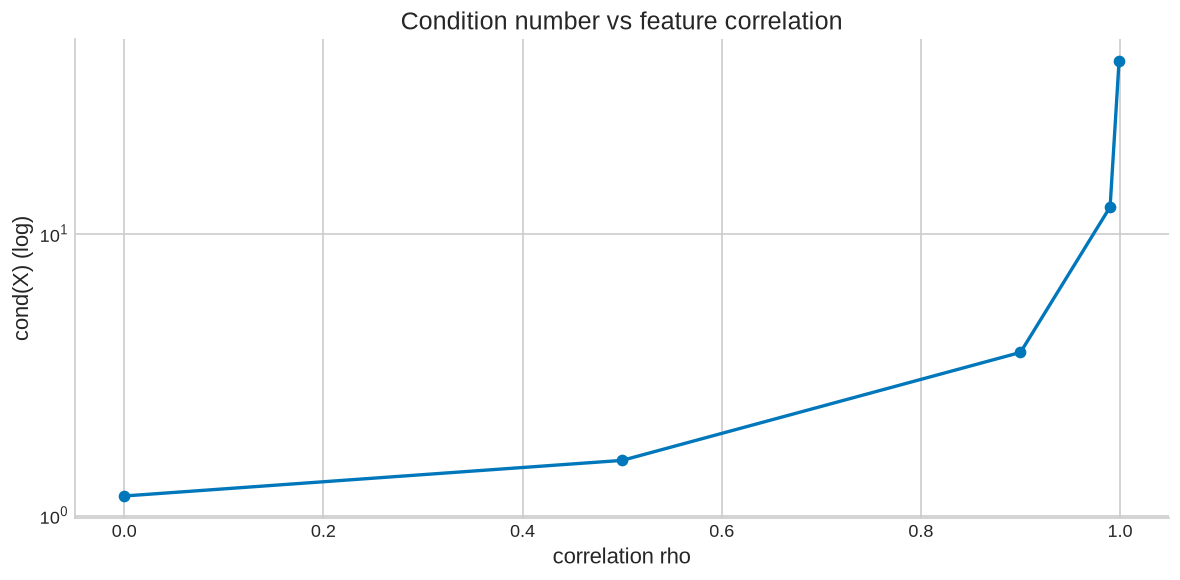

In [32]:

rng = np.random.default_rng(42)
base = rng.normal(size=(200, 1))
conds = []
rhos = [0.0, 0.5, 0.9, 0.99, 0.999]
for rho in rhos:
    X = np.column_stack([base[:, 0], rho * base[:, 0] + np.sqrt(1 - rho**2) * rng.normal(size=200)])
    conds.append(np.linalg.cond(X))
    print(f"rho={rho}: cond(X) = {conds[-1]:.1f}")
check_true("conditioning worsens with correlation", conds[-1] > conds[0] * 10)
Q, _ = np.linalg.qr(np.column_stack([base[:, 0], rng.normal(size=200)]))
check_close("orthonormalised features: cond = 1", np.linalg.cond(Q), 1.0, 1e-8)
fig, ax = plt.subplots()
ax.semilogy(rhos, conds, 'o-', color=WONG[0])
ax.set_title("Condition number vs feature correlation"); ax.set_xlabel("correlation rho"); ax.set_ylabel("cond(X) (log)")
plt.tight_layout(); plt.show()

## 18. QR Least Squares vs Normal Equations: the Squaring Penalty Again

Normal equations square the condition number; QR of A does not. On a collinear design, both are run and their solution errors compared against a known truth - Björck's classical lesson in executable form, echoing Section 03-02's Gram warning for regression.

In [33]:

rng = np.random.default_rng(42)
n = 100
f = rng.normal(size=(n, 1))
X = np.column_stack([f[:, 0], f[:, 0] + 1e-6 * rng.normal(size=n), rng.normal(size=n)])
x_true = np.array([1.0, 2.0, -1.0])
y = X @ x_true
beta_ne = np.linalg.solve(X.T @ X, X.T @ y)
beta_qr, *_ = np.linalg.lstsq(X, y, rcond=None)
print(f"normal equations error: {np.linalg.norm(beta_ne - x_true):.2e}")
print(f"QR/lstsq error:         {np.linalg.norm(beta_qr - x_true):.2e}")
check_true("QR route more accurate on collinear design", np.linalg.norm(beta_qr - x_true) < np.linalg.norm(beta_ne - x_true))
print(f"cond(X) = {np.linalg.cond(X):.1e}; cond(X^T X) = {np.linalg.cond(X.T @ X):.1e}")

normal equations error: 5.84e-05
QR/lstsq error:         1.10e-10
PASS: QR route more accurate on collinear design
cond(X) = 1.6e+06; cond(X^T X) = 2.5e+12


---

## Summary

| Section | Key Concept | Key Formula |
|---------|------------|-------------|
| §1–2 | Inner product, angle, Parseval | $\langle\mathbf{u},\mathbf{v}\rangle = \mathbf{u}^\top\mathbf{v}$; $\|\mathbf{v}\|^2=\sum_i\hat{v}_i^2$ |
| §3 | Orthogonal matrices, $O(n)$ | $Q^\top Q = I$; $\kappa(Q)=1$ |
| §4 | Orthogonal projections | $P = QQ^\top$, $P^2=P$, $P^\top=P$ |
| §5 | Gram-Schmidt (CGS vs MGS) | MGS error $O(\epsilon\kappa)$ vs CGS $O(\epsilon\kappa^2)$ |
| §6–7 | Householder QR | $H=I-2\mathbf{n}\mathbf{n}^\top$; $A=QR$; solve $R\mathbf{x}=Q^\top\mathbf{b}$ |
| §8 | Spectral theorem | $A=Q\Lambda Q^\top$; $\lambda_{\min}\le R_A(\mathbf{x})\le\lambda_{\max}$ |
| §9 | DFT (unitary) | $F_n/\sqrt{n}$ unitary; Parseval in frequency domain |
| §10 | ML: init, RoPE, SN, polar | $Q_{\text{init}}$; $R_m^\top R_n = R_{n-m}$; Newton-Schulz |

**Exercises:** [exercises.ipynb](exercises.ipynb) — 8 graded problems.
**Notes:** [notes.md](notes.md) — full 2000+ line treatment.